# Food Delivery Pricing & Efficiency Analysis

## Project Overview
This project analyses food delivery order data to understand order-value patterns, restaurant performance, customer ratings, food preparation time and delivery efficiency.

## Objectives
- Analyse order-value distribution.
- Identify popular cuisines and restaurants.
- Compare food preparation and delivery times.
- Investigate the relationship between delivery performance and customer ratings.
- Identify operational improvement opportunities.

## Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SQL
- Power BI

## Dataset
NYC Restaurants — Food Ordering and Delivery dataset.

## Project Type
Exploratory Data Analysis and Business Intelligence.


In [ ]:
# Install required libraries
!pip install -q pandas numpy matplotlib seaborn

# **Importing Libraries**

In [ ]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# Loading the Dataset

In [ ]:
from huggingface_hub import hf_hub_download

file_path = hf_hub_download(
    repo_id="jason1966/ahsan81_food-ordering-and-delivery-app-dataset",
    filename="food_order.csv",
    repo_type="dataset"
)

print("Dataset downloaded successfully!")
print("File location:", file_path)

food_order.csv:   0%|          | 0.00/124k [00:00<?, ?B/s]

Dataset downloaded successfully!
File location: /root/.cache/huggingface/hub/datasets--jason1966--ahsan81_food-ordering-and-delivery-app-dataset/snapshots/511051544163b2638cae593e043c365758b57a91/food_order.csv


In [ ]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


# Data Understanding

In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (1898, 9)


In [ ]:
print("Columns:")
print(df.columns.tolist())

Columns:
['order_id', 'customer_id', 'restaurant_name', 'cuisine_type', 'cost_of_the_order', 'day_of_the_week', 'rating', 'food_preparation_time', 'delivery_time']


In [ ]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB

Missing values:
order_id                 0
customer_id              0
restaurant_name          0
cuisine_type             0
cost_of_the_order        0
day_of_the_week          0
rating                   0
food_preparation_time    0
delivery_time            

In [ ]:
df.describe(include="all")

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898,1898,1898.000000,1898,1898,1898.000000,1898.000000
unique,NaN,NaN,178,14,NaN,2,4,NaN,NaN
top,NaN,NaN,Shake Shack,American,NaN,Weekend,Not given,NaN,NaN
freq,NaN,NaN,219,584,NaN,1351,736,NaN,NaN
mean,1.477496e+06,171168.478398,NaN,NaN,16.498851,NaN,NaN,27.371970,24.161749
std,5.480497e+02,113698.139743,NaN,NaN,7.483812,NaN,NaN,4.632481,4.972637
min,1.476547e+06,1311.000000,NaN,NaN,4.470000,NaN,NaN,20.000000,15.000000
25%,1.477021e+06,77787.750000,NaN,NaN,12.080000,NaN,NaN,23.000000,20.000000
50%,1.477496e+06,128600.000000,NaN,NaN,14.140000,NaN,NaN,27.000000,25.000000
75%,1.477970e+06,270525.000000,NaN,NaN,22.297500,NaN,NaN,31.000000,28.000000


In [ ]:
# Check duplicate rows

print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate order IDs
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

Total duplicate rows: 0
Duplicate order IDs: 0


In [ ]:
# Check rating distribution

print(df["rating"].value_counts(dropna=False))

rating
Not given    736
5            588
4            386
3            188
Name: count, dtype: int64


In [ ]:
# Statistical summary of numerical columns

df[
    [
        "cost_of_the_order",
        "food_preparation_time",
        "delivery_time"
    ]
].describe()

,cost_of_the_order,food_preparation_time,delivery_time
count,1898.000000,1898.000000,1898.000000
mean,16.498851,27.371970,24.161749
std,7.483812,4.632481,4.972637
min,4.470000,20.000000,15.000000
25%,12.080000,23.000000,20.000000
50%,14.140000,27.000000,25.000000
75%,22.297500,31.000000,28.000000
max,35.410000,35.000000,33.000000


# Data Cleaning

In [ ]:
# Create a separate cleaned dataset

df_clean = df.copy()

# Convert unavailable ratings into missing values
df_clean["rating"] = df_clean["rating"].replace(
    "Not given", np.nan
)

# Convert ratings into numeric format
df_clean["rating"] = pd.to_numeric(
    df_clean["rating"],
    errors="coerce"
)

# Check the result
print("Rating data type:", df_clean["rating"].dtype)

print("\nRating distribution:")
print(df_clean["rating"].value_counts(dropna=False))

Rating data type: float64

Rating distribution:
rating
NaN    736
5.0    588
4.0    386
3.0    188
Name: count, dtype: int64


In [ ]:
print("Missing ratings:", df_clean["rating"].isna().sum())

print("\nMissing values in all columns:")
print(df_clean.isnull().sum())

print("\nUpdated data types:")
print(df_clean.dtypes)

Missing ratings: 736

Missing values in all columns:
order_id                   0
customer_id                0
restaurant_name            0
cuisine_type               0
cost_of_the_order          0
day_of_the_week            0
rating                   736
food_preparation_time      0
delivery_time              0
dtype: int64

Updated data types:
order_id                   int64
customer_id                int64
restaurant_name           object
cuisine_type              object
cost_of_the_order        float64
day_of_the_week           object
rating                   float64
food_preparation_time      int64
delivery_time              int64
dtype: object


In [ ]:
# Check for invalid numerical values

print("Order values <= 0:")
print((df_clean["cost_of_the_order"] <= 0).sum())

print("\nPreparation times <= 0:")
print((df_clean["food_preparation_time"] <= 0).sum())

print("\nDelivery times <= 0:")
print((df_clean["delivery_time"] <= 0).sum())

print("\nInvalid ratings:")
print((~df_clean["rating"].isin([1, 2, 3, 4, 5]) &
       df_clean["rating"].notna()).sum())

Order values <= 0:
0

Preparation times <= 0:
0

Delivery times <= 0:
0

Invalid ratings:
0


In [ ]:
# Identify potential outliers using IQR

numerical_columns = [
    "cost_of_the_order",
    "food_preparation_time",
    "delivery_time"
]

for column in numerical_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_limit) |
        (df_clean[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Potential outliers:", len(outliers))


Column: cost_of_the_order
Lower limit: -3.246249999999998
Upper limit: 37.62375
Potential outliers: 0

Column: food_preparation_time
Lower limit: 11.0
Upper limit: 43.0
Potential outliers: 0

Column: delivery_time
Lower limit: 8.0
Upper limit: 40.0
Potential outliers: 0


In [ ]:
# Inspect unique categorical values

categorical_columns = [
    "restaurant_name",
    "cuisine_type",
    "day_of_the_week"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts())


restaurant_name:
restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
                            ... 
Rye House                      1
Hiroko's Place                 1
Frank Restaurant               1
Sarabeth's West                1
'wichcraft                     1
Name: count, Length: 178, dtype: int64

cuisine_type:
cuisine_type
American          584
Japanese          470
Italian           298
Chinese           215
Mexican            77
Indian             73
Middle Eastern     49
Mediterranean      46
Thai               19
French             18
Southern           17
Korean             13
Spanish            12
Vietnamese          7
Name: count, dtype: int64

day_of_the_week:
day_of_the_week
Weekend    1351
Weekday     547
Name: count, dtype: int64


# Exploratory Data Analysis (EDA)

In [ ]:
# Count orders by day type

day_counts = df_clean["day_of_the_week"].value_counts()

print(day_counts)

day_of_the_week
Weekend    1351
Weekday     547
Name: count, dtype: int64


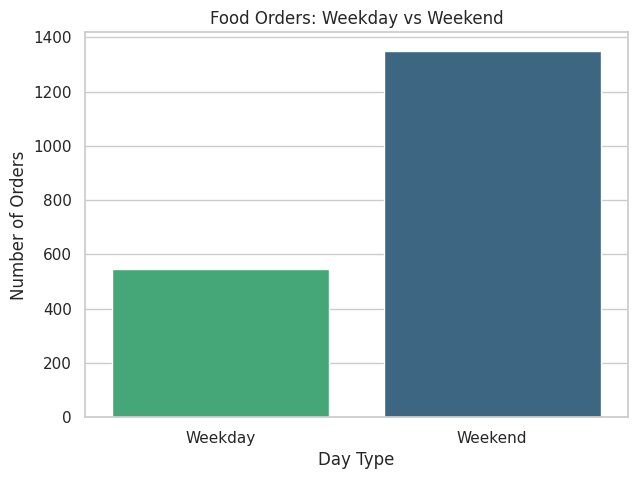

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="day_of_the_week",
    hue="day_of_the_week",
    order=["Weekday", "Weekend"],
    palette="viridis",
    legend=False
)

plt.title("Food Orders: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")

plt.show()

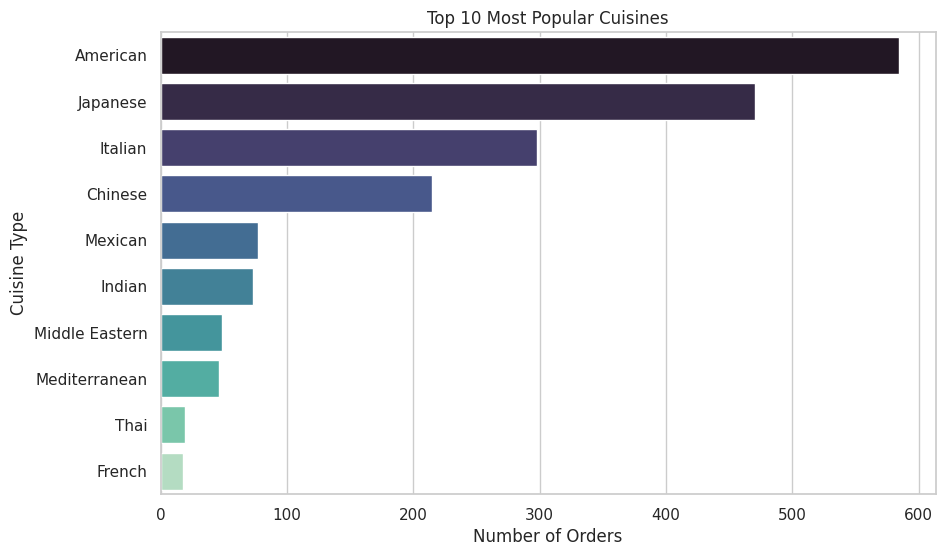

In [ ]:
cuisine_counts = (
    df_clean["cuisine_type"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=cuisine_counts.values,
    y=cuisine_counts.index,
    hue=cuisine_counts.index,
    palette="mako",
    legend=False
)

plt.title("Top 10 Most Popular Cuisines")
plt.xlabel("Number of Orders")
plt.ylabel("Cuisine Type")

plt.show()

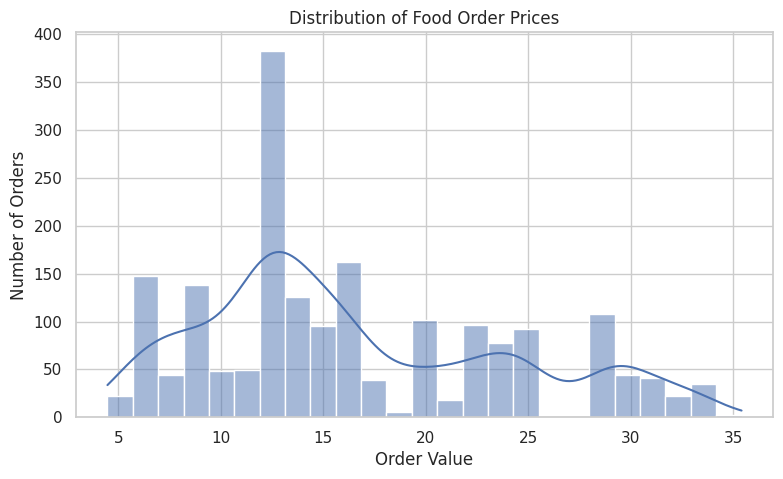

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="cost_of_the_order",
    bins=25,
    kde=True
)

plt.title("Distribution of Food Order Prices")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

In [ ]:
print("Average order value:",
      round(df_clean["cost_of_the_order"].mean(), 2))

print("Median order value:",
      round(df_clean["cost_of_the_order"].median(), 2))

print("Highest order value:",
      df_clean["cost_of_the_order"].max())

Average order value: 16.5
Median order value: 14.14
Highest order value: 35.41


In [ ]:
# Calculate average delivery time by day type

delivery_by_day = (
    df_clean.groupby("day_of_the_week")["delivery_time"]
    .mean()
    .reset_index()
)

print(delivery_by_day)

  day_of_the_week  delivery_time
0         Weekday      28.340037
1         Weekend      22.470022


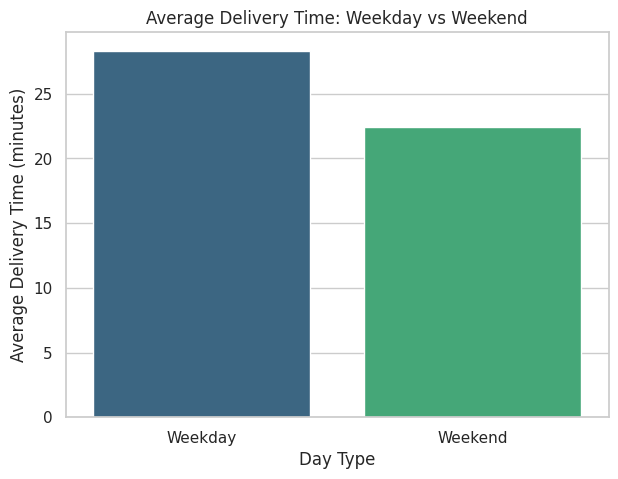

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=delivery_by_day,
    x="day_of_the_week",
    y="delivery_time",
    hue="day_of_the_week",
    order=["Weekday", "Weekend"],
    palette="viridis",
    legend=False
)

plt.title("Average Delivery Time: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Delivery Time (minutes)")

plt.show()

In [ ]:
# Average preparation time by day type

prep_by_day = (
    df_clean.groupby("day_of_the_week")["food_preparation_time"]
    .mean()
    .reset_index()
)

print(prep_by_day)

  day_of_the_week  food_preparation_time
0         Weekday              27.212066
1         Weekend              27.436714


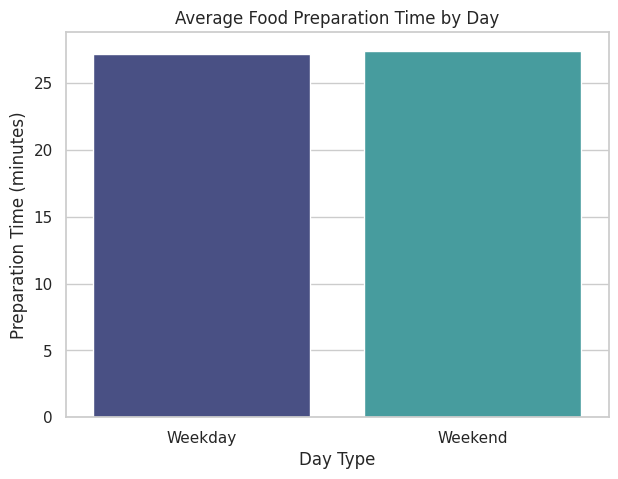

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=prep_by_day,
    x="day_of_the_week",
    y="food_preparation_time",
    hue="day_of_the_week",
    order=["Weekday", "Weekend"],
    palette="mako",
    legend=False
)

plt.title("Average Food Preparation Time by Day")
plt.xlabel("Day Type")
plt.ylabel("Preparation Time (minutes)")

plt.show()

In [ ]:
# Compare preparation and delivery times

performance_summary = (
    df_clean.groupby("day_of_the_week")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Preparation_Time=("food_preparation_time", "mean"),
        Avg_Delivery_Time=("delivery_time", "mean")
    )
    .round(2)
)

print(performance_summary)

                 Total_Orders  Avg_Preparation_Time  Avg_Delivery_Time
day_of_the_week                                                       
Weekday                   547                 27.21              28.34
Weekend                  1351                 27.44              22.47


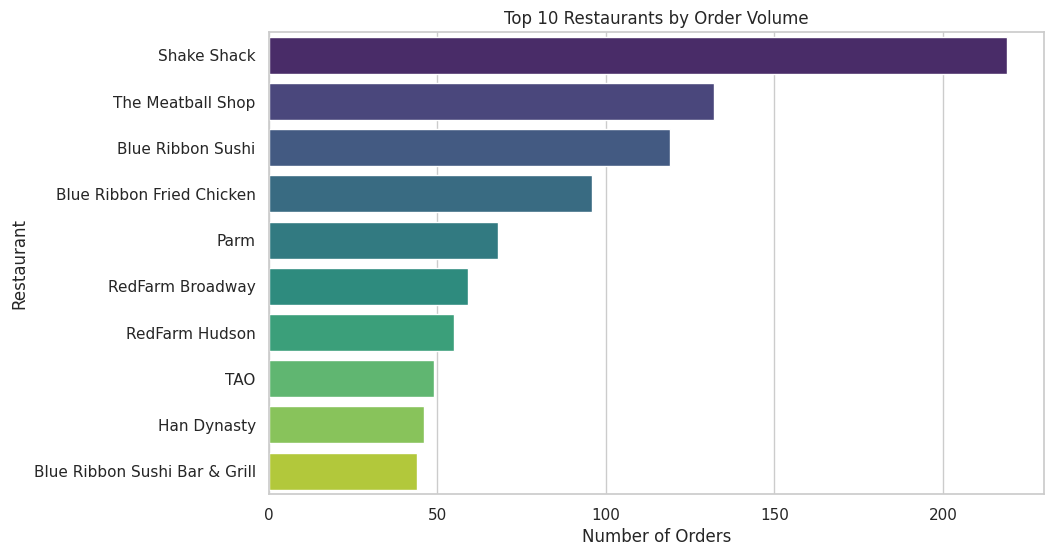

In [ ]:
# Top 10 restaurants by order volume

top_restaurants = (
    df_clean["restaurant_name"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_restaurants.values,
    y=top_restaurants.index,
    hue=top_restaurants.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Restaurants by Order Volume")
plt.xlabel("Number of Orders")
plt.ylabel("Restaurant")

plt.show()

### Key Business Insights — Weekday vs Weekend

1. Weekend orders account for approximately 71.2% of all recorded orders, indicating substantially higher demand during weekends.
2. Average food preparation time remains relatively stable, at 27.21 minutes on weekdays and 27.44 minutes on weekends.
3. Average delivery time is lower on weekends (22.47 minutes) than on weekdays (28.34 minutes), a difference of approximately 20.7%.
4. Higher order volume does not necessarily correspond to longer delivery times in this dataset.

**Business implication:** Food delivery businesses should investigate weekday delivery delays and plan operational resources according to actual demand and delivery performance patterns.

# Restaurant Performance Analysis

In [ ]:
# Calculate order volume and average preparation time

restaurant_performance = (
    df_clean.groupby("restaurant_name")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Preparation_Time=("food_preparation_time", "mean"),
        Avg_Delivery_Time=("delivery_time", "mean")
    )
    .sort_values("Total_Orders", ascending=False)
)

# Display top 10 restaurants

print(restaurant_performance.head(10).round(2))

                               Total_Orders  Avg_Preparation_Time  \
restaurant_name                                                     
Shake Shack                             219                 27.95   
The Meatball Shop                       132                 27.18   
Blue Ribbon Sushi                       119                 27.92   
Blue Ribbon Fried Chicken                96                 27.20   
Parm                                     68                 27.31   
RedFarm Broadway                         59                 27.59   
RedFarm Hudson                           55                 27.16   
TAO                                      49                 26.78   
Han Dynasty                              46                 27.41   
Blue Ribbon Sushi Bar & Grill            44                 26.30   

                               Avg_Delivery_Time  
restaurant_name                                   
Shake Shack                                24.66  
The Meatball Shop 

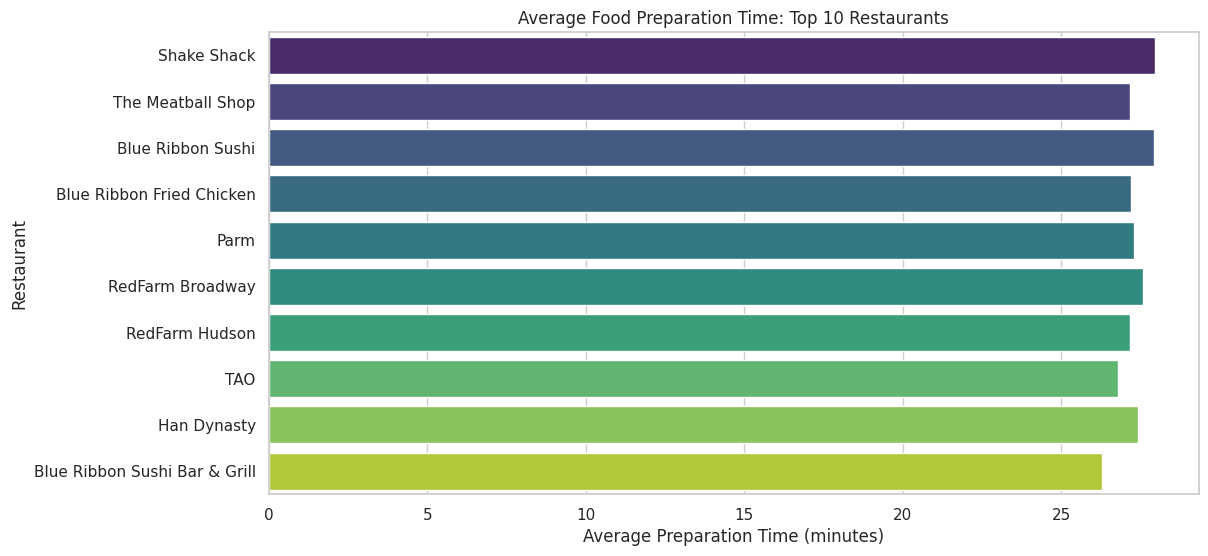

In [ ]:
top_10_performance = restaurant_performance.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_performance,
    x="Avg_Preparation_Time",
    y="restaurant_name",
    hue="restaurant_name",
    palette="viridis",
    legend=False
)

plt.title("Average Food Preparation Time: Top 10 Restaurants")
plt.xlabel("Average Preparation Time (minutes)")
plt.ylabel("Restaurant")

plt.show()

In [ ]:
# Calculate correlation between order volume
# and average preparation time

correlation = restaurant_performance[
    ["Total_Orders", "Avg_Preparation_Time", "Avg_Delivery_Time"]
].corr()

print("Restaurant Performance Correlation:")
print(correlation.round(3))

Restaurant Performance Correlation:
                      Total_Orders  Avg_Preparation_Time  Avg_Delivery_Time
Total_Orders                 1.000                 0.019             -0.009
Avg_Preparation_Time         0.019                 1.000              0.056
Avg_Delivery_Time           -0.009                 0.056              1.000


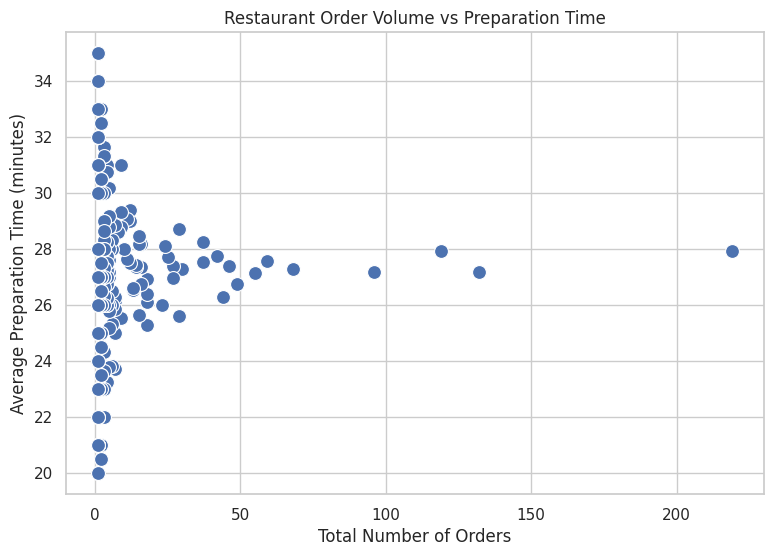

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=restaurant_performance.reset_index(),
    x="Total_Orders",
    y="Avg_Preparation_Time",
    s=100
)

plt.title("Restaurant Order Volume vs Preparation Time")
plt.xlabel("Total Number of Orders")
plt.ylabel("Average Preparation Time (minutes)")

plt.show()

### Restaurant Performance and Correlation Analysis

The correlation analysis revealed very weak linear relationships between restaurant order volume, average food preparation time, and average delivery time.

- Order volume vs preparation time: 0.019
- Order volume vs delivery time: -0.009
- Preparation time vs delivery time: 0.056

**Business insight:** Restaurants with higher order volumes do not necessarily experience longer average preparation or delivery times. Therefore, restaurant popularity alone may not be a reliable indicator of operational efficiency.

Further investigation using individual order characteristics would be needed to identify the factors influencing delivery performance.

In [ ]:
# Calculate average order value by cuisine

cuisine_pricing = (
    df_clean.groupby("cuisine_type")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Order_Value=("cost_of_the_order", "mean"),
        Total_Revenue=("cost_of_the_order", "sum")
    )
    .sort_values("Avg_Order_Value", ascending=False)
)

print(cuisine_pricing.round(2))

                Total_Orders  Avg_Order_Value  Total_Revenue
cuisine_type                                                
French                    18            19.79         356.29
Southern                  17            19.30         328.11
Thai                      19            19.21         364.95
Spanish                   12            18.99         227.93
Middle Eastern            49            18.82         922.21
Mexican                   77            16.93        1303.85
Indian                    73            16.92        1235.14
Italian                  298            16.42        4892.77
American                 584            16.32        9530.78
Chinese                  215            16.31        3505.62
Japanese                 470            16.30        7663.13
Mediterranean             46            15.47         711.84
Korean                    13            14.00         182.02
Vietnamese                 7            12.88          90.18


### Cuisine Pricing and Revenue Analysis

1. French cuisine recorded the highest average order value at 19.79, followed by Southern at 19.30 and Thai at 19.21.
2. American cuisine generated the highest total revenue of 9,530.78 because it had the highest order volume (584 orders).
3. Japanese cuisine ranked second in total revenue at 7,663.13.
4. Vietnamese cuisine recorded the lowest average order value at 12.88.

**Business recommendation:** Food delivery businesses should consider both average order value and order volume when evaluating cuisine performance. High-value cuisines may offer opportunities for premium positioning, while high-volume cuisines can contribute substantially to overall revenue.

*Note: Revenue represents the sum of recorded order values, not business profit.*

In [ ]:
day_pricing = (
    df_clean.groupby("day_of_the_week")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Order_Value=("cost_of_the_order", "mean"),
        Total_Revenue=("cost_of_the_order", "sum")
    )
)

print(day_pricing.round(2))

                 Total_Orders  Avg_Order_Value  Total_Revenue
day_of_the_week                                              
Weekday                   547            16.31        8922.22
Weekend                  1351            16.57       22392.60


In [ ]:
# Restaurant revenue analysis

restaurant_revenue = (
    df_clean.groupby("restaurant_name")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Order_Value=("cost_of_the_order", "mean"),
        Total_Revenue=("cost_of_the_order", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

print(restaurant_revenue.head(10).round(2))

                               Total_Orders  Avg_Order_Value  Total_Revenue
restaurant_name                                                            
Shake Shack                             219            16.34        3579.53
The Meatball Shop                       132            16.25        2145.21
Blue Ribbon Sushi                       119            16.00        1903.95
Blue Ribbon Fried Chicken                96            17.32        1662.29
Parm                                     68            16.36        1112.76
RedFarm Broadway                         59            16.36         965.13
RedFarm Hudson                           55            16.75         921.21
TAO                                      49            17.03         834.50
Han Dynasty                              46            16.42         755.29
Blue Ribbon Sushi Bar & Grill            44            15.15         666.62


### Weekday vs Weekend Pricing Analysis

- Weekend orders generated 22,392.60 in total order value, compared with 8,922.22 on weekdays.
- Average order value was relatively similar: 16.57 on weekends and 16.31 on weekdays.
- Weekend orders accounted for approximately 71.2% of all orders.
- Weekend revenue was approximately 2.51 times weekday revenue.

**Business recommendation:** Businesses should focus on managing higher weekend order demand and maintaining operational efficiency rather than assuming that weekend revenue growth comes from higher customer spending.

*Revenue figures represent recorded order values, not net profit.*

# Delivery Efficiency Analysis

In [ ]:
restaurant_delivery = (
    df_clean.groupby("restaurant_name")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Preparation_Time=("food_preparation_time", "mean"),
        Avg_Delivery_Time=("delivery_time", "mean")
    )
    .sort_values("Avg_Delivery_Time", ascending=True)
)

print("10 Fastest Restaurants by Average Delivery Time:")
print(restaurant_delivery.head(10).round(2))

print("\n10 Slowest Restaurants by Average Delivery Time:")
print(restaurant_delivery.tail(10).sort_values(
    "Avg_Delivery_Time", ascending=False
).round(2))

10 Fastest Restaurants by Average Delivery Time:
                   Total_Orders  Avg_Preparation_Time  Avg_Delivery_Time
restaurant_name                                                         
Gaia Italian Cafe             1                  25.0               15.0
Hibino                        1                  28.0               15.0
Paul & Jimmy's                1                  33.0               15.0
The MasalaWala                1                  32.0               15.0
Galli Restaurant              1                  22.0               16.0
Coppola's East                1                  32.0               16.0
Wo Hop Restaurant             1                  22.0               16.0
Market Table                  1                  21.0               17.0
Byblos Restaurant             2                  32.5               18.0
Samurai Mama                  1                  21.0               18.0

10 Slowest Restaurants by Average Delivery Time:
                       To

In [ ]:
# Consider restaurants with at least 10 orders
reliable_restaurants = restaurant_delivery[
    restaurant_delivery["Total_Orders"] >= 10
].copy()

# Find fastest and slowest among these restaurants
fastest_reliable = reliable_restaurants.sort_values(
    "Avg_Delivery_Time"
).head(10)

slowest_reliable = reliable_restaurants.sort_values(
    "Avg_Delivery_Time", ascending=False
).head(10)

print("10 Fastest Restaurants (Minimum 10 Orders):")
print(fastest_reliable.round(2))

print("\n10 Slowest Restaurants (Minimum 10 Orders):")
print(slowest_reliable.round(2))

10 Fastest Restaurants (Minimum 10 Orders):
                            Total_Orders  Avg_Preparation_Time  \
restaurant_name                                                  
Westville Hudson                      15                 25.67   
Sushi of Gari                         16                 28.19   
Hill Country Fried Chicken            14                 27.36   
Jack's Wife Freda                     25                 27.72   
Otto Enoteca Pizzeria                 12                 29.00   
Cafe Mogador                          18                 25.28   
Burger Joint                          12                 27.50   
Han Dynasty                           46                 27.41   
RedFarm Broadway                      59                 27.59   
TAO                                   49                 26.78   

                            Avg_Delivery_Time  
restaurant_name                                
Westville Hudson                        21.73  
Sushi of Gari      

In [ ]:
# Overall rating distribution
rating_counts = df_clean["rating"].value_counts().sort_index()

print("Customer Rating Distribution:")
print(rating_counts)

print("\nAverage Customer Rating:")
print(round(df_clean["rating"].mean(), 2))

print("\nTotal Rated Orders:")
print(df_clean["rating"].count())

print("\nOrders Without Ratings:")
print(df_clean["rating"].isna().sum())

Customer Rating Distribution:
rating
3.0    188
4.0    386
5.0    588
Name: count, dtype: int64

Average Customer Rating:
4.34

Total Rated Orders:
1162

Orders Without Ratings:
736


In [ ]:
cuisine_ratings = (
    df_clean.dropna(subset=["rating"])
    .groupby("cuisine_type")
    .agg(
        Total_Ratings=("rating", "count"),
        Avg_Rating=("rating", "mean")
    )
    .sort_values("Avg_Rating", ascending=False)
)

print("Cuisine-wise Customer Ratings:")
print(cuisine_ratings.round(2))

Cuisine-wise Customer Ratings:
                Total_Ratings  Avg_Rating
cuisine_type                             
Spanish                     6        4.83
Thai                        9        4.67
Indian                     50        4.54
Mexican                    48        4.42
Japanese                  273        4.37
Italian                   172        4.36
Chinese                   133        4.34
Southern                   13        4.31
French                     10        4.30
American                  368        4.30
Middle Eastern             34        4.24
Mediterranean              32        4.22
Korean                      9        4.11
Vietnamese                  5        4.00


In [ ]:
rating_delivery_analysis = (
    df_clean.dropna(subset=["rating"])
    .groupby("rating")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Delivery_Time=("delivery_time", "mean"),
        Avg_Preparation_Time=("food_preparation_time", "mean")
    )
)

print("Delivery and Preparation Time by Customer Rating:")
print(rating_delivery_analysis.round(2))

Delivery and Preparation Time by Customer Rating:
        Total_Orders  Avg_Delivery_Time  Avg_Preparation_Time
rating                                                       
3.0              188              24.56                 27.43
4.0              386              23.87                 27.40
5.0              588              24.21                 27.36


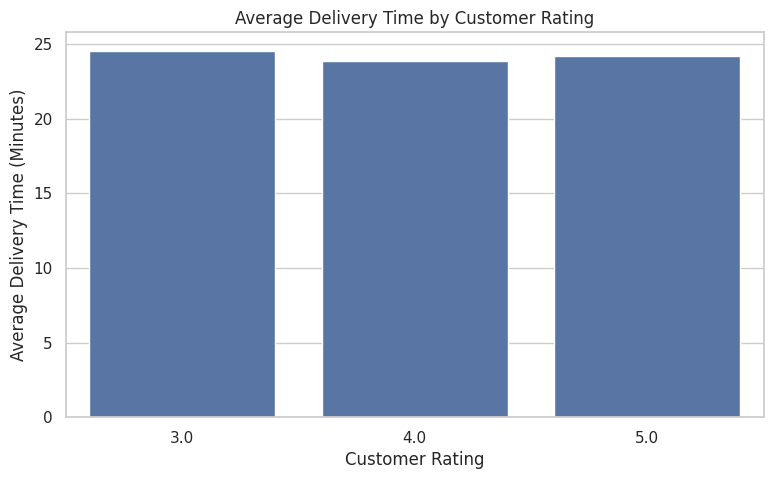

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rating_delivery_analysis.reset_index(),
    x="rating",
    y="Avg_Delivery_Time"
)

plt.title("Average Delivery Time by Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Average Delivery Time (Minutes)")
plt.show()

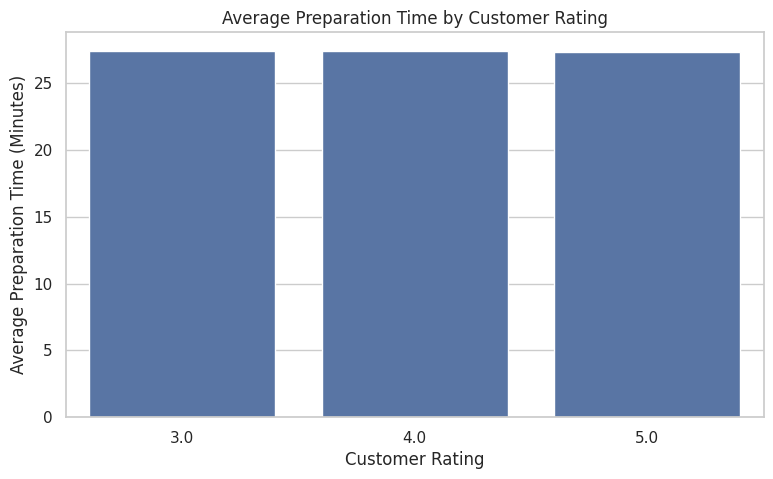

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rating_delivery_analysis.reset_index(),
    x="rating",
    y="Avg_Preparation_Time"
)

plt.title("Average Preparation Time by Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Average Preparation Time (Minutes)")
plt.show()


# Customer Satisfaction Analysis

In [ ]:
restaurant_ratings = (
    df_clean.dropna(subset=["rating"])
    .groupby("restaurant_name")
    .agg(
        Total_Ratings=("rating", "count"),
        Avg_Rating=("rating", "mean")
    )
)

# Keep restaurants with at least 10 customer ratings
reliable_restaurant_ratings = restaurant_ratings[
    restaurant_ratings["Total_Ratings"] >= 10
]

# Highest-rated restaurants
top_rated_restaurants = reliable_restaurant_ratings.sort_values(
    "Avg_Rating", ascending=False
).head(10)

print("Top 10 Restaurants by Customer Rating:")
print(top_rated_restaurants.round(2))

# Lowest-rated restaurants
lowest_rated_restaurants = reliable_restaurant_ratings.sort_values(
    "Avg_Rating"
).head(10)

print("\n10 Lowest-Rated Restaurants:")
print(lowest_rated_restaurants.round(2))

Top 10 Restaurants by Customer Rating:
                               Total_Ratings  Avg_Rating
restaurant_name                                         
The Kati Roll Company                     10        4.70
Sushi of Gari Tribeca                     13        4.62
Blue Ribbon Sushi Bar & Grill             22        4.59
Five Guys Burgers and Fries               18        4.56
The Meatball Shop                         84        4.51
Han Dynasty                               23        4.43
The Smile                                 12        4.42
J. G. Melon                               12        4.42
Tamarind TriBeCa                          20        4.40
Hill Country Fried Chicken                11        4.36

10 Lowest-Rated Restaurants:
                                       Total_Ratings  Avg_Rating
restaurant_name                                                 
Bareburger                                        17        4.06
Rubirosa                                          24

In [ ]:
restaurant_performance = (
    df_clean.dropna(subset=["rating"])
    .groupby("restaurant_name")
    .agg(
        Total_Ratings=("rating", "count"),
        Avg_Rating=("rating", "mean"),
        Avg_Delivery_Time=("delivery_time", "mean")
    )
)

# Keep restaurants with at least 10 ratings
restaurant_performance = restaurant_performance[
    restaurant_performance["Total_Ratings"] >= 10
]

# Calculate correlation
correlation = restaurant_performance[
    ["Avg_Rating", "Avg_Delivery_Time"]
].corr()

print("Restaurant Rating and Delivery Time Correlation:")
print(correlation.round(3))

Restaurant Rating and Delivery Time Correlation:
                   Avg_Rating  Avg_Delivery_Time
Avg_Rating              1.000             -0.343
Avg_Delivery_Time      -0.343              1.000


In [ ]:
order_value_rating = (
    df_clean.dropna(subset=["rating"])
    .groupby("rating")
    .agg(
        Total_Orders=("order_id", "count"),
        Avg_Order_Value=("cost_of_the_order", "mean")
    )
)

print("Order Value by Customer Rating:")
print(order_value_rating.round(2))

Order Value by Customer Rating:
        Total_Orders  Avg_Order_Value
rating                               
3.0              188            16.22
4.0              386            16.71
5.0              588            16.97


##  Business Recommendations

Based on the analysis, the following recommendations can help improve food delivery operations:

### 1. Improve Weekday Delivery Efficiency
Average delivery time was higher on weekdays (28.34 minutes) than weekends (22.47 minutes). The business could investigate weekday delivery operations, including traffic conditions, delivery distance, and driver availability.

### 2. Focus on High-Performing Restaurants
Restaurants such as Shake Shack and The Meatball Shop recorded high order volumes. Maintaining service quality and efficient order handling at these restaurants could support customer satisfaction and business performance.

### 3. Monitor Restaurants with Longer Delivery Times
Restaurants with relatively high average delivery times should be reviewed to identify possible operational bottlenecks. Further investigation into preparation, delivery distance, and driver allocation may help identify improvement opportunities.

### 4. Improve Customer Feedback Collection
A substantial number of orders had no recorded customer rating. Encouraging customers to provide feedback could help the business understand customer experiences more effectively.

### 5. Monitor Customer Satisfaction
The analysis found a negative correlation (-0.343) between average restaurant delivery time and average customer rating. Monitoring delivery performance alongside customer feedback may help identify restaurants that need operational improvements.

### 6. Use Order Value Insights for Planning
Weekend orders accounted for 71.2% of all orders. Businesses could use this pattern to plan staffing, restaurant coordination, and delivery capacity during busy periods.

##  Conclusion

This project analyzed a food delivery dataset containing 1,898 orders to understand pricing patterns, restaurant performance, delivery efficiency, and customer satisfaction.

The analysis revealed that weekend orders represented 71.2% of total orders. American cuisine recorded the highest order volume, while French cuisine had the highest average order value, based on a relatively small number of orders.

Restaurant-level analysis highlighted differences in order volume, delivery performance, and customer ratings. The customer satisfaction analysis showed an overall average rating of 4.34 out of 5.

A negative correlation of -0.343 was observed between average restaurant delivery time and average customer rating, suggesting that longer delivery times tend to be associated with lower ratings.

Overall, this project provided practical experience in data cleaning, exploratory data analysis, data visualization, aggregation, and correlation analysis using Python.

The findings demonstrate how data analysis can help businesses understand customer behavior, monitor operational performance, and identify potential areas for improvement.